# Ray Serve: HTTP proxy settings and status

An HTTP proxy config node starts Serve on 127.0.0.1:8123 before the app is deployed, and a status node reads serve.status() afterwards.

**When to use it.** Running Serve on a non-default host or port, and checking deployment health from code.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

> **Experimental.** The builder lists a node in this graph in its *Experimental* section, so the node may change in later releases of the builder. The generated code ran on Ray 2.55.1.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

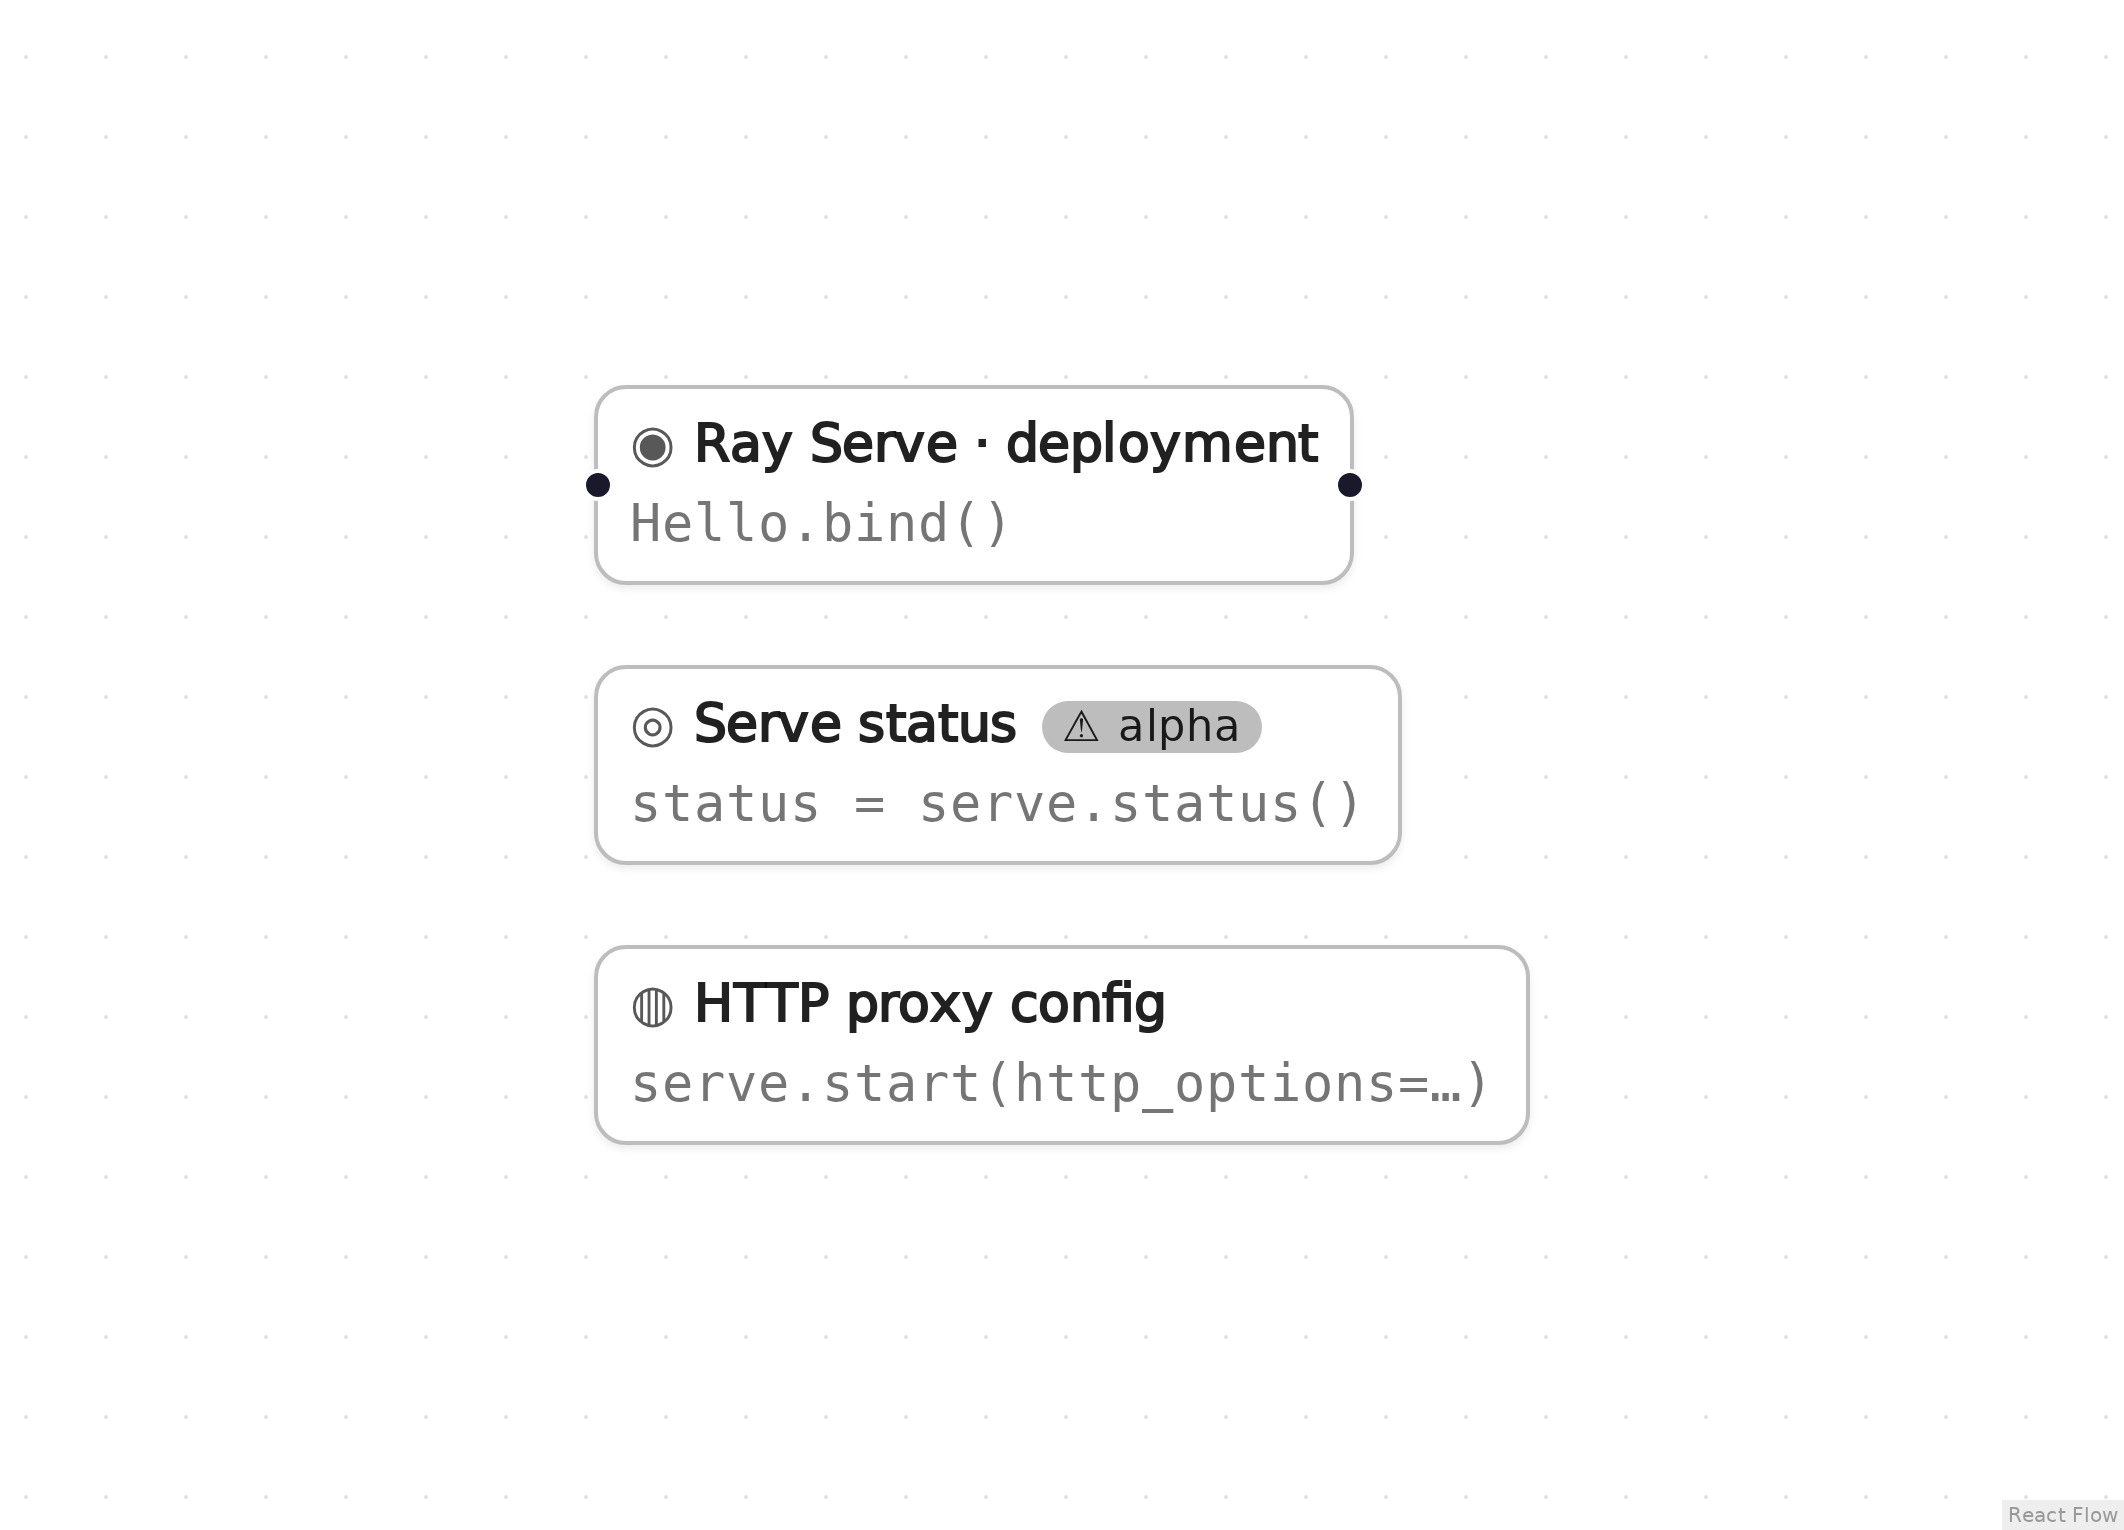

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
from ray import serve
from starlette.requests import Request


@serve.deployment
class Hello:
    def __call__(self, request: Request) -> str:
        return "hello from port 8123"

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

from ray import serve
import ray
from ray.serve.config import HTTPOptions

if not ray.is_initialized():
    ray.init()

serve.start(http_options=HTTPOptions(host="127.0.0.1", port=8123))
_deploy_n1 = Hello.bind()
serve.run(_deploy_n1)
status = serve.status()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
import urllib.request

with urllib.request.urlopen("http://127.0.0.1:8123/", timeout=30) as resp:
    text = resp.read().decode()
assert text == "hello from port 8123", text
assert status.applications["default"].status == "RUNNING", status.applications
print(text, "; app status:", status.applications["default"].status)

hello from port 8123 ; app status: ApplicationStatus.RUNNING


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–5 and 7–8)

```python
# Generated with Eugo's visual Ray builder
...
from ray import serve
import ray
from ray.serve.config import HTTPOptions
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**HTTP proxy config** (node `h1`, line 10)

```python
serve.start(http_options=HTTPOptions(host="127.0.0.1", port=8123))
```

serve.start(http_options=HTTPOptions(host="127.0.0.1", port=8123)) configures the proxy; it must run before the first serve.run.

**Deployment** (node `n1`, lines 11–12)

```python
_deploy_n1 = Hello.bind()
serve.run(_deploy_n1)
```

A plain HTTP deployment.

**Serve status** (node `s1`, line 13)

```python
status = serve.status()
```

serve.status() returns application and deployment states after the app is up.

## Clean up

Shut down Serve and then Ray, so the next notebook starts fresh.

In [5]:
from ray import serve

serve.shutdown()
ray.shutdown()